# Simple Multimodal Test

Compare 3 models to assess performance:

1. Trained only one one modality
2. Trained jointly on all modalities as vector output
3. One main model with separate models for other modalities as additional input

In [1]:
from time import perf_counter as timer

import numpy as np
import torch
import itertools
import matplotlib.pyplot as plt
import pyro
from pyro.infer import NUTS, MCMC, Predictive
from pyro.infer.autoguide import init_to_sample
import pyro.distributions as dist
from pyro.contrib.autoname import scope


import mmbo.examples.testfunc as testfunc
from mmbo.nn import TIBNN, LayeredTIBNN


In [2]:
##### Put all future computations on GPU

device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
torch.set_default_device(device)

In [3]:
# Consistent network parameters
width = 1000
depth = 1
output_bias = True
bias_ordering = False
bias_positive = False
residual_prior = dist.Exponential(5)
#residual_prior = dist.LogNormal(np.log(0.1), np.log(np.sqrt(10)))
#residual_prior = dist.HalfCauchy(1)

# Consistent sampling parameters
warmup_steps = 150
num_samples = 50
num_chains = 1

In [4]:
def plot_predictions(model, mcmc, x_plot, y_plot, x_train, y_train, pred_site="mu"):
    x_train, y_train, y_plot = x_train.cpu(), y_train.cpu(), y_plot.cpu()
    x_plot, x_plot_orig = x_plot.cpu(), x_plot
    # Set up figure/axes
    fig, ax = plt.subplots(figsize=(10, 5))
    xlims = [1.05*x_plot.min() - 0.05*x_plot.max(), 1.05*x_plot.max() - 0.05*x_plot.min()]
    ylims = [1.5*y_plot.min() - 0.5*y_plot.max(), 1.5*y_plot.max() - 0.5*y_plot.min()]
    plt.xlim(xlims)
    plt.ylim(ylims)
    plt.xlabel("X", fontsize=30)
    plt.ylabel("Y", fontsize=30)
    # Plot predicted means
    preds = Predictive(model, mcmc.get_samples(), return_sites=[pred_site])(x_plot_orig)
    preds[pred_site] = preds[pred_site].cpu()
    for inst in range(preds[pred_site].shape[0]):
        y_inst = preds[pred_site][inst,:,-1]
        ax.plot(x_plot.squeeze(), y_inst, '-', linewidth=0.5, alpha=0.2, color="red", zorder = 0)
    # Plot confidence bands
    y_pred_mean = preds[pred_site].mean(0)[:,-1]
    y_pred_std = preds[pred_site].std(0)[:,-1]
    ax.plot(x_plot.squeeze(), y_pred_mean, '-', linewidth=3, color="#408765", label="predictive mean", zorder = 10)
    ax.fill_between(x_plot.squeeze(), y_pred_mean - 2 * y_pred_std, y_pred_mean + 2 * y_pred_std, alpha=0.6, color='#86cfac', zorder=5)
    # Plot true function
    ax.plot(x_plot.squeeze(), y_plot.squeeze(), 'b-', linewidth=3, label="true function", zorder = 15)
    # Plot data points
    ax.plot(x_train.squeeze(), y_train.squeeze(), 'ko', markersize=4, label="observations", zorder = 20)
    plt.legend(loc="lower right")

## Generate test data

In [5]:
def _train_data(func, modes, xmin, xmax, ntrainpergroup, seed, full, shuffle):
    rng = np.random.default_rng(seed)
    ntrain = ntrainpergroup * (2 ** len(modes) - 1)
    # Training Data
    X_train = np.linspace(xmin, xmax, num=ntrain)
    if shuffle:
        rng.shuffle(X_train)
    Y_train = np.empty((ntrain, len(modes)))
    Y_train.fill(np.nan)
    combinations = list(itertools.chain.from_iterable([itertools.combinations(range(len(modes)), r) for r in range(1,len(modes)+1)])) * ntrainpergroup
    for r in range(ntrain):
        for c in combinations[r]:
            Y_train[r,c] = func(X_train[r], modes[c])
    Y_train_full = np.zeros((ntrain, len(modes)))
    for i,m in enumerate(modes):
        Y_train_full[:,i] = func(X_train, m)
    # Package and return
    X_train_pt = torch.tensor(np.float32(X_train.reshape((ntrain,1))))
    Y_train_pt = torch.tensor(np.float32(Y_train))
    Y_train_full_pt = torch.tensor(np.float32(Y_train_full))
    if full:
        return X_train_pt, Y_train_pt, Y_train_full_pt
    else:
        return X_train_pt, Y_train_pt

def _molecule_train_data(func, xmin, xmax, ntrainpergroup, seed, full, shuffle):
    modes = func.modes
    return _train_data(func, modes, xmin, xmax, ntrainpergroup, seed, full, shuffle)

def li2_train_data(ntrainpergroup, seed=None, full=False, shuffle=True):
    return _molecule_train_data(testfunc.li2_energy, 0.5, 11.0, ntrainpergroup, seed, full, shuffle)

def be2_train_data(ntrainpergroup, seed=None, full=False, shuffle=True):
    return _molecule_train_data(testfunc.be2_energy, 0.5, 5.0, ntrainpergroup, seed, full, shuffle)

def nice_periodic_train_data(ntrainpergroup, nummodes=5, seed=None, full=False, shuffle=True):
    return _train_data(testfunc.nice_periodic, list(range(nummodes)), -np.pi, np.pi, ntrainpergroup, seed, full, shuffle)

Text(0.5, 1.0, 'Training Data')

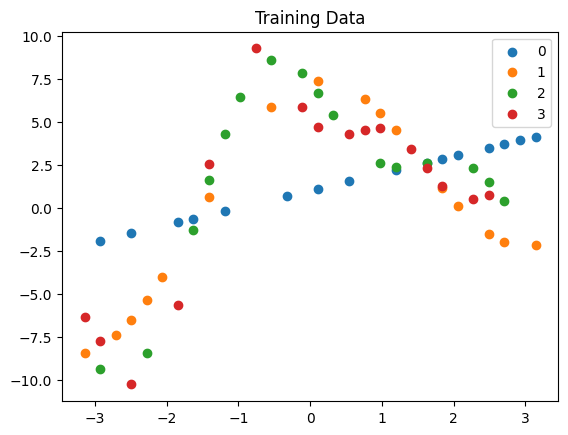

In [6]:
n_modes = 4

X_train, Y_train, Y_train_full = nice_periodic_train_data(2, n_modes, 1234, full=True)

X_plot, _, Y_plot = nice_periodic_train_data(100, n_modes, 1234, full=True, shuffle=False)

for i,m in enumerate(range(n_modes)):
    plt.scatter(X_train.cpu().detach(), Y_train.cpu().detach()[:,i], label=m)
plt.legend(loc="upper right")
plt.title("Training Data")

## 1. Single Modality Model

In [7]:
pyro.set_rng_seed(2024)

In [8]:
single = TIBNN.from_data(X_train, Y_train[:,-1:], width = width, depth = depth, residual_prior = residual_prior,
                         output_bias = output_bias, bias_ordering = bias_ordering, bias_positive = bias_positive)

nuts_single = NUTS(single, jit_compile = True, full_mass = False, init_strategy = init_to_sample)

# Sample
mcmc_single = MCMC(nuts_single, num_samples = num_samples, warmup_steps = warmup_steps, num_chains = num_chains, mp_context = "spawn")
start_single = timer()
mcmc_single.run(X_train, Y_train[:,-1:])
stop_single = timer()
print("Elapsed time: {:.1f}s".format(stop_single - start_single))

Sample: 100%|██████████| 200/200 [09:39,  2.90s/it, step size=3.96e-03, acc. prob=0.837]

Elapsed time: 579.4s


In [9]:
single.chain[0].weight.device

device(type='cuda', index=0)

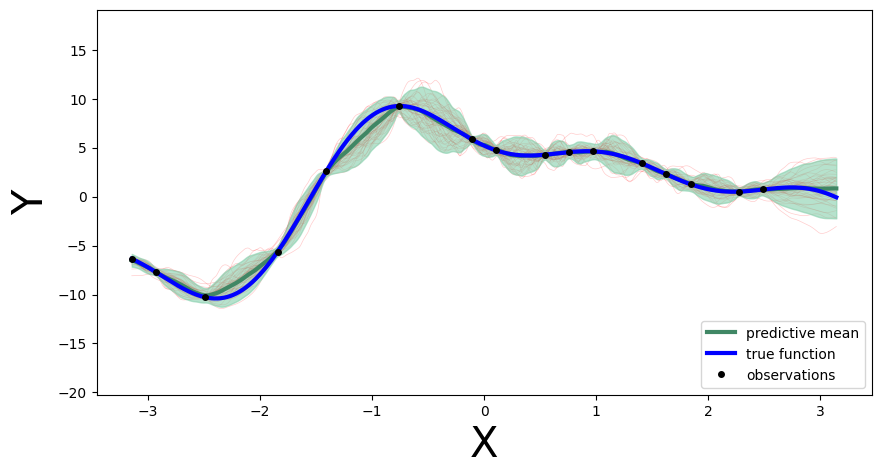

In [10]:
plot_predictions(single, mcmc_single, X_plot, Y_plot[:,-1:], X_train, Y_train[:,-1:])

In [11]:
print("Sigma mean: ", mcmc_single.get_samples()['sigma'].mean(dim=0))
print("Sigma std: ", mcmc_single.get_samples()['sigma'].std(dim=0))

Sigma mean:  tensor([0.2289], device='cuda:0')
Sigma std:  tensor([0.1912], device='cuda:0')


## 2. Joint output Model

In [12]:
multiple = TIBNN.from_data(X_train, Y_train, width = width, depth = depth, residual_prior = residual_prior,
                         output_bias = output_bias, bias_ordering = bias_ordering, bias_positive = bias_positive)

nuts_multiple = NUTS(multiple, jit_compile = True, full_mass = False, init_strategy = init_to_sample)

# Sample
mcmc_multiple = MCMC(nuts_multiple, num_samples = num_samples, warmup_steps = warmup_steps, num_chains = num_chains, mp_context = "spawn")
start_multiple = timer()
mcmc_multiple.run(X_train, Y_train)
stop_multiple = timer()
print("Elapsed time: {:.1f}s".format(stop_multiple - start_multiple))

Sample: 100%|██████████| 200/200 [09:35,  2.88s/it, step size=1.53e-03, acc. prob=0.901]

Elapsed time: 575.5s


In [13]:
X_train.device

device(type='cuda', index=0)

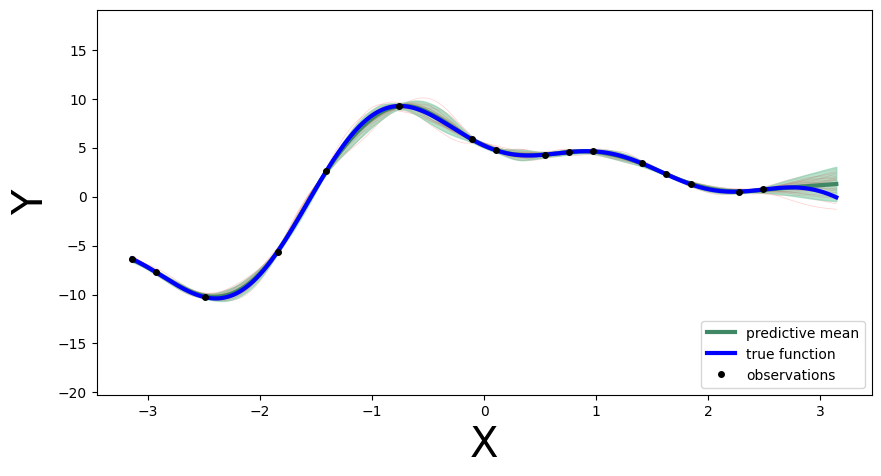

In [14]:
plot_predictions(multiple, mcmc_multiple, X_plot, Y_plot[:,-1:], X_train, Y_train[:,-1:])

In [15]:
print("Sigma mean: ", mcmc_multiple.get_samples()['sigma'].mean(dim=0))
print("Sigma std: ", mcmc_multiple.get_samples()['sigma'].std(dim=0))

Sigma mean:  tensor([0.0217, 0.0214, 0.1824, 0.1422], device='cuda:0')
Sigma std:  tensor([0.0046, 0.0020, 0.0421, 0.0531], device='cuda:0')


## 3. Separate Model with Predictors

In [16]:
layered = LayeredTIBNN.from_data(X_train, Y_train[:,:-1], Y_train[:,-1:], width = width, depth = depth, residual_prior = residual_prior,
                         output_bias = output_bias, bias_ordering = bias_ordering, bias_positive = bias_positive)

nuts_layered = NUTS(layered, jit_compile = True, full_mass = False, init_strategy = init_to_sample)

# Sample
mcmc_layered = MCMC(nuts_layered, num_samples = num_samples, warmup_steps = warmup_steps, num_chains = num_chains, mp_context = "spawn")
start_layered = timer()
mcmc_layered.run(X_train, Y_train[:,:-1], Y_train[:,-1:])
stop_layered = timer()
print("Elapsed time: {:.1f}s".format(stop_layered - start_layered))

Sample: 100%|██████████| 200/200 [16:40,  5.00s/it, step size=2.18e-03, acc. prob=0.718]

Elapsed time: 1000.0s


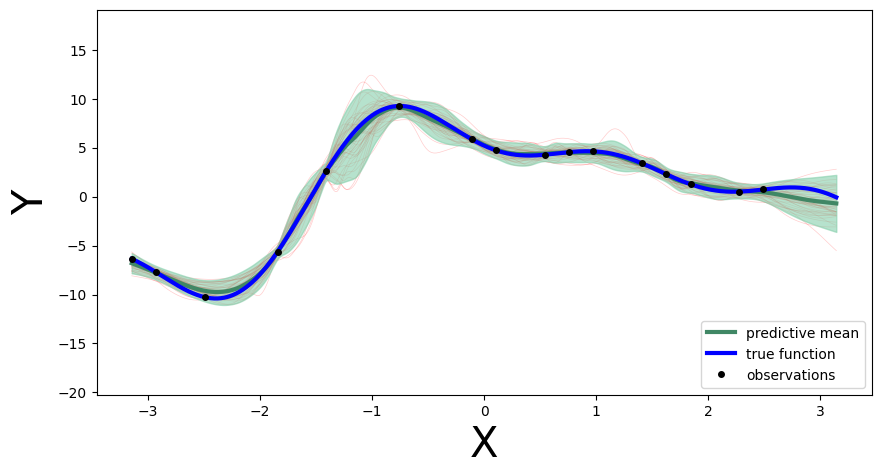

In [17]:
plot_predictions(layered, mcmc_layered, X_plot, Y_plot[:,-1:], X_train, Y_train[:,-1:], pred_site="second/mu")

# 4. Removing one useful data source

In [18]:
select_3 = [0,1,3]
X_train_3, Y_train_3, Y_train_full_3 = X_train, Y_train[:,select_3], Y_train_full[:,select_3]
X_plot_3, Y_plot_3 = X_plot, Y_plot[:,select_3]

## 4a. Joint output model

In [19]:
multiple_3 = TIBNN.from_data(X_train_3, Y_train_3, width = width, depth = depth, residual_prior = residual_prior,
                         output_bias = output_bias, bias_ordering = bias_ordering, bias_positive = bias_positive)

nuts_multiple_3 = NUTS(multiple_3, jit_compile = True, full_mass = False, init_strategy = init_to_sample)

# Sample
mcmc_multiple_3 = MCMC(nuts_multiple_3, num_samples = num_samples, warmup_steps = warmup_steps, num_chains = num_chains, mp_context = "spawn")
start_multiple_3 = timer()
mcmc_multiple_3.run(X_train_3, Y_train_3)
stop_multiple_3 = timer()
print("Elapsed time: {:.1f}s".format(stop_multiple_3 - start_multiple_3))

Sample: 100%|██████████| 200/200 [09:03,  2.72s/it, step size=2.42e-03, acc. prob=0.729]

Elapsed time: 543.9s


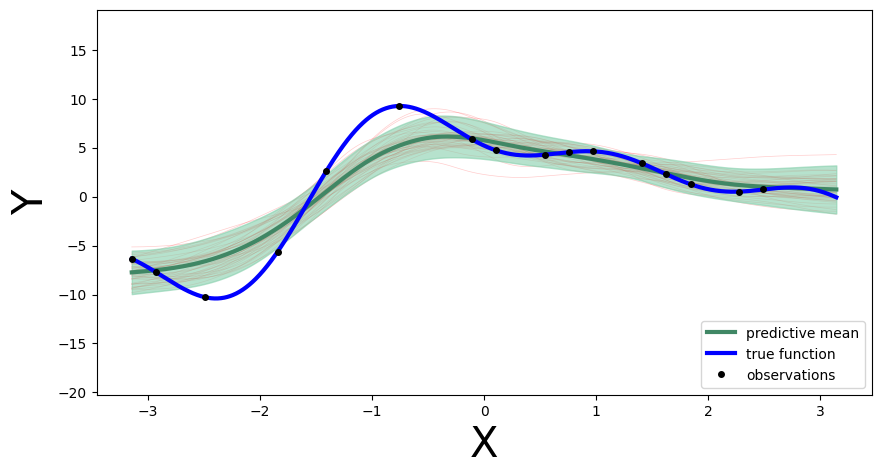

In [20]:
plot_predictions(multiple_3, mcmc_multiple_3, X_plot_3, Y_plot_3[:,-1:], X_train_3, Y_train_3[:,-1:])

## 4b. Layered model

In [21]:
layered_3 = LayeredTIBNN.from_data(X_train_3, Y_train_3[:,:-1], Y_train_3[:,-1:], width = width, depth = depth, residual_prior = residual_prior,
                         output_bias = output_bias, bias_ordering = bias_ordering, bias_positive = bias_positive)

nuts_layered_3 = NUTS(layered_3, jit_compile = True, full_mass = False, init_strategy = init_to_sample)

# Sample
mcmc_layered_3 = MCMC(nuts_layered_3, num_samples = num_samples, warmup_steps = warmup_steps, num_chains = num_chains, mp_context = "spawn")
start_layered_3 = timer()
mcmc_layered_3.run(X_train_3, Y_train_3[:,:-1], Y_train_3[:,-1:])
stop_layered_3 = timer()
print("Elapsed time: {:.1f}s".format(stop_layered_3 - start_layered_3))

Warmup:  25%|██▌       | 50/200 [03:18,  5.46s/it, step size=1.10e-04, acc. prob=0.785]

In [ ]:
plot_predictions(layered_3, mcmc_layered_3, X_plot_3, Y_plot_3[:,-1:], X_train_3, Y_train_3[:,-1:], pred_site="second/mu")